#Download the files data files 

import sys

assert sys.version_info >= (3, 10)

In [2]:
import sys
import sklearn
assert sys.version_info >= (3, 10)

In [4]:
# Download thge data 

from pathlib import Path
import pandas as pd
import tarfile
import urllib.request

In [8]:
def load_data():
    tarball = Path("data\\housing.tgz")
    if not tarball.is_file():
        Path("data").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball)
        with tarfile.open(tarball) as housing_tarball:
            housing_tarball.extractall(path="data", filter="data")
    return pd.read_csv(Path("data/housing/housing.csv"))

housing_full = load_data()

In [9]:
#  describe the data
housing_full.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [10]:
# lets look at the ocean_proximiity column closer
housing_full["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [11]:
#  describe the data
housing_full.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


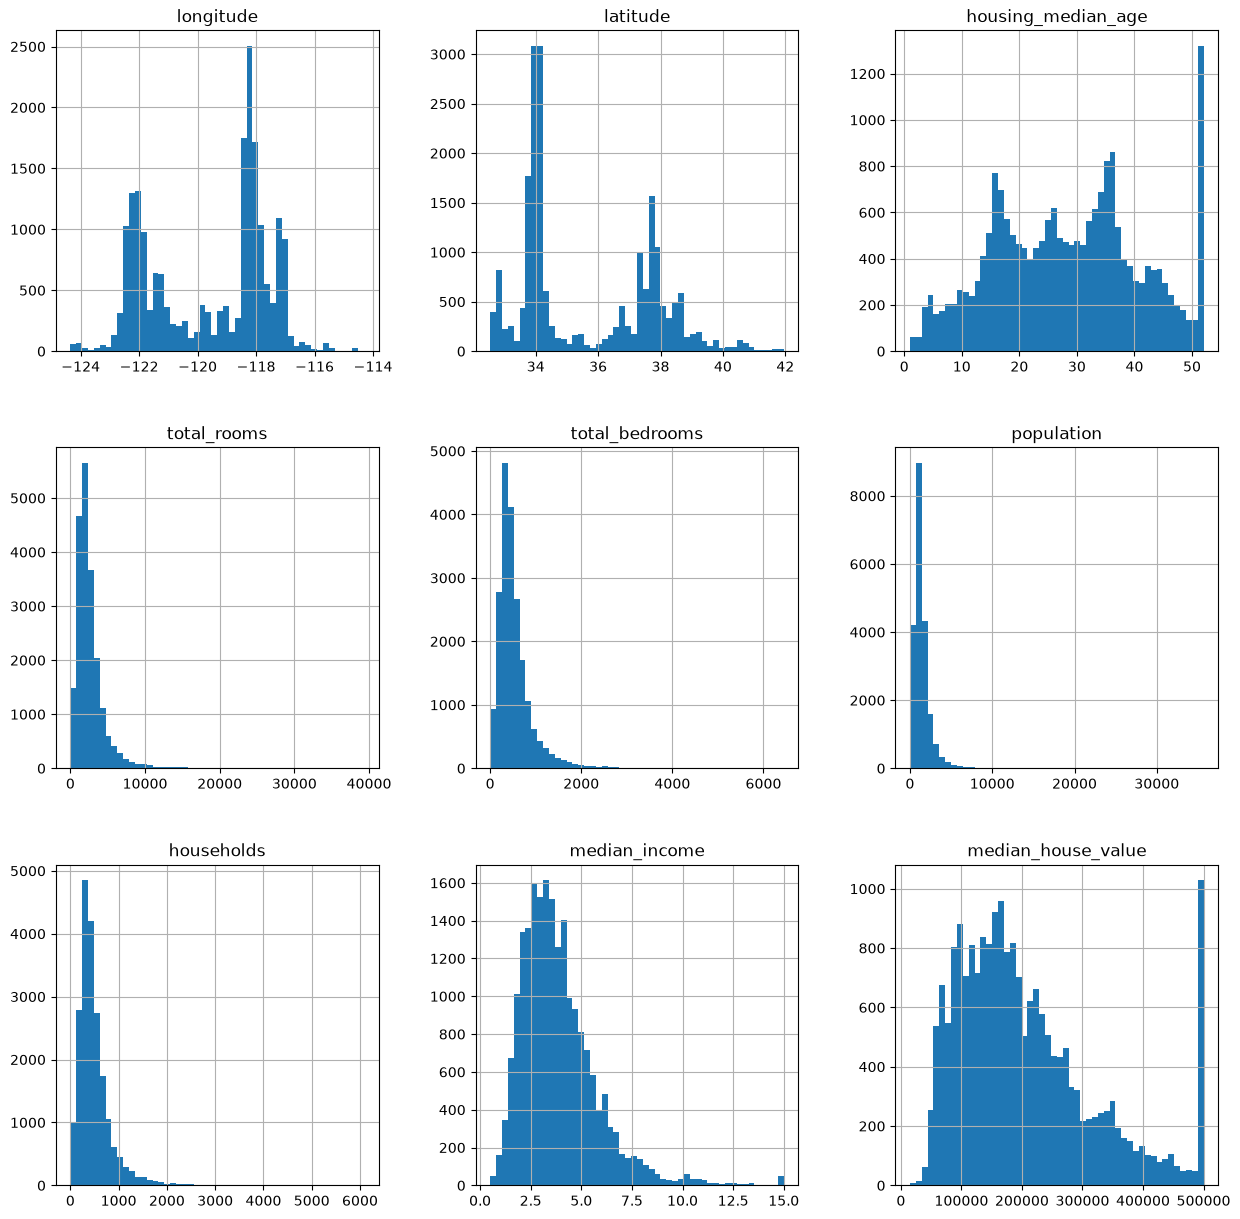

In [13]:
import matplotlib.pyplot as plt

housing_full.hist(bins=50, figsize=(15,15))
plt.show()

In [16]:
# Creating a test and traning data set
# 1. we split the exising data in to 80  20 rule 80 percent for traning and 20 percent for testing.

import numpy as np

def shuffle_and_split_data(data, test_ratio, rng):
    shuffled_indices = rng.permutation(len(data))
    test_set_size = int(len(data) * test_ratio)
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    return data.iloc[train_indices], data.iloc[test_indices]

rng = np.random.default_rng()
training_set, test_set = shuffle_and_split_data(housing_full, 0.2, rng)
print("length of traning set",len(training_set))
print("length of test set",len(test_set))

length of traning set 16512
length of test set 4128


In [22]:
housing_full

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [30]:
# Do this split form scipy
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(housing_full, test_size=0.2, random_state=42)



In [ ]:
# so far we have split the data in to test and train randomly, this could work in some cases but there is not logic behind the split 
# what so i mean bu logic for exampole if you take in the US the population split in gender is 51.6% female and 48.4% male
# if i had to choose 1000 people in random for some tesing i would like to expect the 1000 smaple size to represent the polulation for a controlled trial if male or female sample are higher then usual then this is called sample bias 
# meaning while traning i have not had proper sampole to to cover all sceanerios that this could lead to unexpected outcome
# hence we would choose a sample stratergy called stratified sampline where we woudl tell the buckets we want the samples to repewsennt and 
# this can be done easily with below function

In [36]:
housing_full['income_category'] = pd.cut(housing_full["median_income"]
                                         ,bins=[0.0,1.5,3.0,4.5,6, np.inf],
                                         labels=[1,2,3,4,5])

In [37]:
housing_full

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,income_category
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,5
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,5
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,5
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,4
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,3
...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND,2
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND,2
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND,2
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND,2


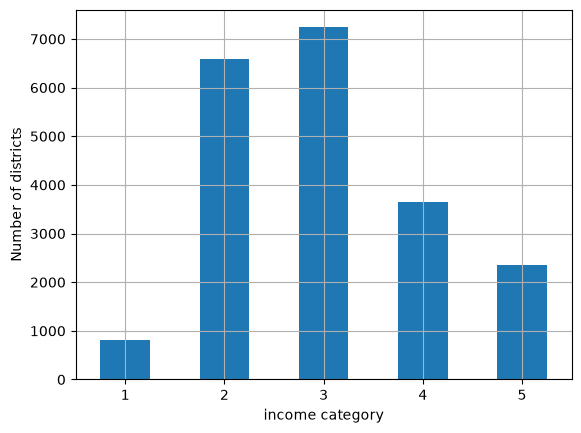

In [39]:
# lets visualize this
cat_counts = housing_full["income_category"].value_counts().sort_index()
cat_counts.plot.bar(rot=0, grid=True)
plt.xlabel("income category")
plt.ylabel("Number of districts")

plt.show()

In [40]:
#   Split using stratified split
strat_train, strat_test = train_test_split(
    housing_full, test_size=0.2, stratify=housing_full["income_category"], random_state=42
)

In [41]:
strat_test["income_category"].value_counts() / len(strat_test)

income_category
3    0.350533
2    0.318798
4    0.176357
5    0.114341
1    0.039971
Name: count, dtype: float64

In [46]:
# lets compare this split to the actual data and see if the split is good for us

def income_cat_proportions(data):
    return data["income_category"].value_counts() / len(data)


train_set,  test_set = train_test_split(housing_full, test_size=0.2, random_state=42)

compare_props = pd.DataFrame({
    "overall %": income_cat_proportions(housing_full),
    "Stratified %": income_cat_proportions(strat_test),
    "random %": income_cat_proportions(test_set)
}).sort_index()

compare_props.index.name = "Income Categry"
compare_props["strat. Error %"] = (compare_props["Stratified %"] / compare_props["overall %"] -1 )
compare_props["Random. Error %"] = (compare_props["random %"] / compare_props["overall %"] -1 )

(compare_props *  100).round(2)

,overall %,Stratified %,random %,strat. Error %,Random. Error %
Income Categry,,,,,
1,3.98,4.00,4.24,0.36,6.45
2,31.88,31.88,30.74,-0.02,-3.59
3,35.06,35.05,34.52,-0.01,-1.53
4,17.63,17.64,18.41,0.03,4.42
5,11.44,11.43,12.09,-0.08,5.63


In [49]:
# lets drop the income category as we wont user that moving forward

for set_ in (strat_test, strat_train):
    set_.drop("income_category", axis=1, inplace=True)

C:\Users\FusionGamingMasterPc\AppData\Local\Temp\ipykernel_24408\2023566677.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  set_.drop("income_category", axis=1, inplace=True)


# Explore and Visualize the Data to Gain Insights

In [51]:
# lets make a copy of our traning data set as we have successfully split the data as per our statisfication lets try to explpre the data visually and find the nuaounces in the data

housing = strat_train.copy()

<Axes: xlabel='longitude', ylabel='latitude'>

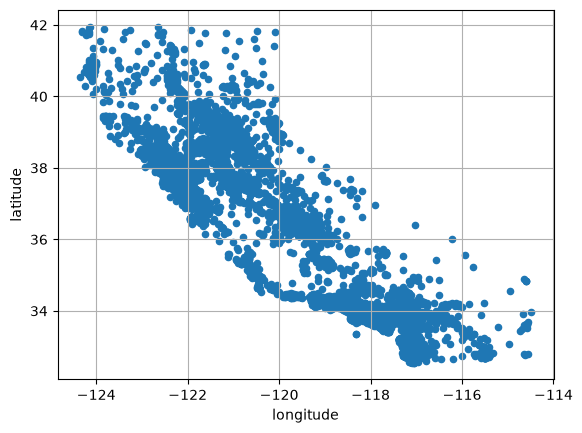

In [52]:
# scatter plot on the lat and longitude

housing.plot(kind="scatter", x="longitude", y="latitude",  grid=True)

<Axes: xlabel='longitude', ylabel='latitude'>

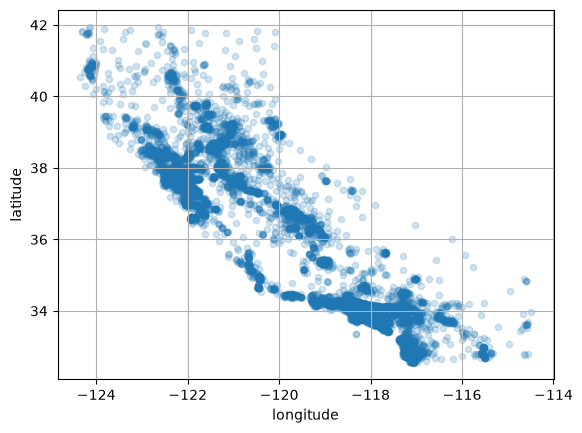

In [ ]:
# lets turn on the density for the map
housing.plot(kind="scatter", x="longitude", y="latitude",  grid=True, alpha=0.2)

<Axes: xlabel='longitude', ylabel='latitude'>

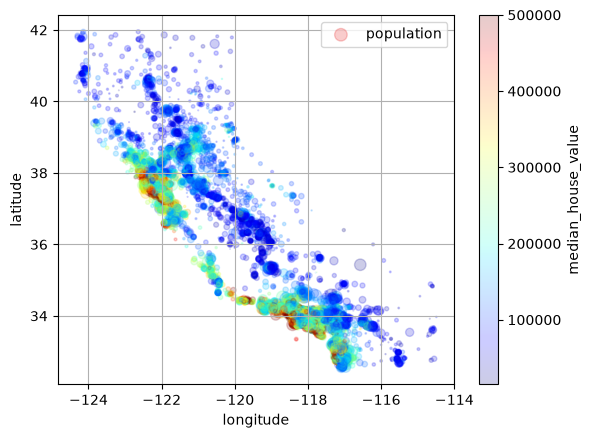

In [64]:
# lets turn on the density for the map
housing.plot(kind="scatter", x="longitude", y="latitude",  grid=True, alpha=0.2,
             s=housing["population"]/100, label="population",
             c="median_house_value", cmap="jet", colorbar=True,
             legend=True)


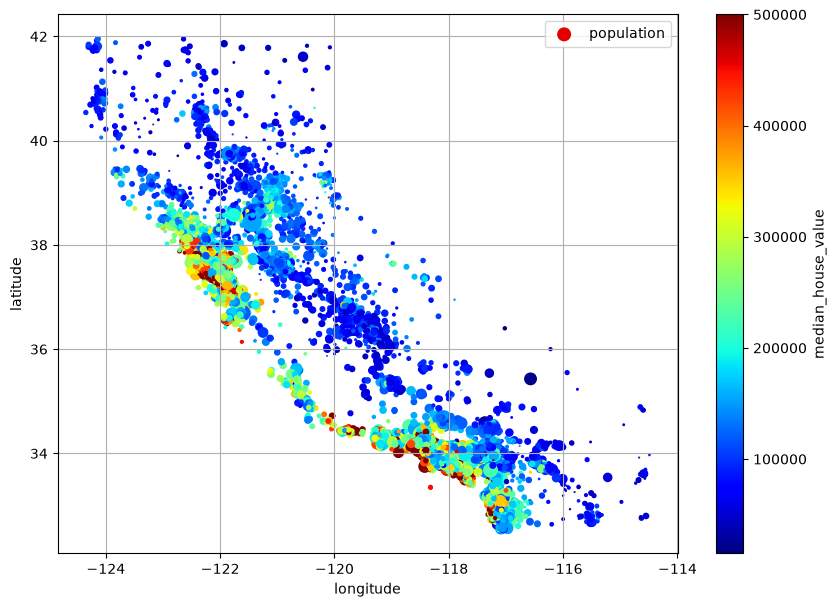

In [71]:
# lets turn on the density for the map
housing.plot(kind="scatter", x="longitude", y="latitude",  grid=True,
             s=housing["population"]/100, label="population",
             c="median_house_value", cmap="jet", colorbar=True,
             legend=True, sharex=False, figsize=(10,7))
plt.show()

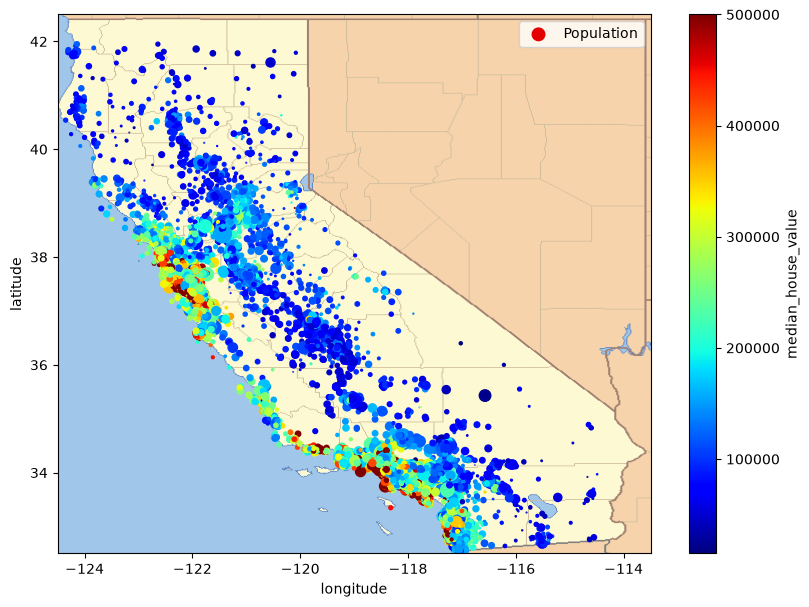

In [ ]:
filename = "california_2.png"
filepath  = Path(f"data\\{filename}")


# lets plot
housing.plot( kind = "scatter", x="longitude", 
             y="latitude", s=housing["population"]/100, 
             label="Population", c="median_house_value", 
             cmap="jet", colorbar=True, legend=True, sharex=False, 
             figsize=(10,7))

california_img = plt.imread(filepath)
axis = -124.5, -113.5, 32.5, 42.5
plt.axis(axis)
plt.imshow(california_img, extent=axis)

plt.show()